# Dispensador de pastillas por voz (KWS)

Las celdas 0 a 17 siguen **el flujo de tu ejercicio** (espectrograma, normalización, CNN, 80 épocas, TFLite sin cuantizar, float16, int8 y sus matrices, más una celda que revisa cuál cabe en el Nano). En la Celda 7 hay 4 arquitecturas, la Celda 8 las compara y en la Celda 9 eliges cuál entrenar. Las celdas 18 a 23 son el dispensador: decisión, prueba con test, escucha continua, exportación y pruebas con audio.

**Datos:** `IA/audio_micro/training/` y `IA/audio_micro/testing/` en tu Drive (tal como salen del export de Edge Impulse).

| Cajón | Pastilla | Servo |
|---|---|---|
| 1 | Dolex | 36° |
| 2 | Advil | 72° |
| 3 | Aspirina | 108° |
| 4 | Omeprazol | 144° |
| 5 | Losartán | 180° |

La etiqueta es lo que va antes del primer punto en el nombre del archivo (`dolex.xxxx.wav`). No importan mayúsculas ni tildes: `Losartán.xxx.wav` y `losartan.xxx.wav` cuentan como la misma clase.

Celda 0

In [1]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


Celda 1

In [2]:
# Dependencias
import os, random, json, shutil, subprocess
from base64 import b64decode
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from IPython import display


SEED = 1
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

Celda 2 – Configuración (lo único que cambias)

In [3]:
import unicodedata

def etiqueta(nombre_archivo):
    """'Losartán.abc.wav' -> 'losartan' (sin mayúsculas ni tildes)."""
    e = nombre_archivo.split('.')[0].strip().lower()
    return ''.join(ch for ch in unicodedata.normalize('NFD', e) if unicodedata.category(ch) != 'Mn')

BASE = '/content/gdrive/MyDrive/IA/audio_micro/'      # ⚠️ carpeta que contiene training/ y testing/
CLASES = ['dolex', 'advil', 'aspirina', 'omeprazol', 'losartan']     # en el orden de los cajones 1 a 5
if any(etiqueta(f) == 'desconocido' for f in os.listdir(BASE + 'training/')):
    CLASES.append('desconocido')        # se usa solo si algún día grabas audios 'desconocido'

DIR_TRAIN = BASE + 'training/'
DIR_TEST  = BASE + 'testing/'
DESCONOCIDO = 'desconocido'

# --- Dispensador (valores de ejemplo, se calibran con el hardware) ---
PASTILLAS = [c for c in CLASES if c != DESCONOCIDO]
COMPARTIMENTO = {p: i + 1 for i, p in enumerate(PASTILLAS)}
ANGULO_SERVO  = {c: round(180 * c / len(PASTILLAS)) for c in COMPARTIMENTO.values()}
ANGULO_REPOSO = 0               # el servo vuelve aquí después de dispensar
UMBRAL = 0.80                   # confianza mínima para dispensar
CONFIRMACIONES = 2              # escucha continua: ventanas seguidas que deben coincidir
PASO_S = 0.25                   # escucha continua: cada cuánto se analiza una ventana
ENFRIAMIENTO_S = 1.5            # escucha continua: tiempo sin escuchar después de dispensar

def load_wav_16k_mono(filename):
    file_contents = tf.io.read_file(filename)
    wav, sample_rate = tf.audio.decode_wav(file_contents, desired_channels=1)
    wav = tf.squeeze(wav, axis=-1)
    return wav

print("CLASES:", CLASES)
for p in PASTILLAS:
    print(f"   cajón {COMPARTIMENTO[p]}: {p:10s} -> servo {ANGULO_SERVO[COMPARTIMENTO[p]]}°")

# Revisión de los datos: cuántos audios hay por clase y si sobra o falta alguna etiqueta
for nombre, d in [('training', DIR_TRAIN), ('testing', DIR_TEST)]:
    fs_ = [f for f in os.listdir(d) if f.lower().endswith('.wav')]
    conteo = {c: sum(etiqueta(f) == c for f in fs_) for c in CLASES}
    raras = sorted({etiqueta(f) for f in fs_} - set(CLASES))
    print(f"{nombre}: {len(fs_)} audios | {conteo}")
    assert not raras, f"En {nombre} hay etiquetas que no están en CLASES: {raras}. Corrige el nombre o agrégalas a CLASES."
    faltan = [c for c, n in conteo.items() if n == 0]
    assert not faltan, f"En {nombre} no hay audios de: {faltan}"

CLASES: ['dolex', 'advil', 'aspirina', 'omeprazol', 'losartan']
   cajón 1: dolex      -> servo 36°
   cajón 2: advil      -> servo 72°
   cajón 3: aspirina   -> servo 108°
   cajón 4: omeprazol  -> servo 144°
   cajón 5: losartan   -> servo 180°
training: 200 audios | {'dolex': 40, 'advil': 40, 'aspirina': 40, 'omeprazol': 40, 'losartan': 40}
testing: 50 audios | {'dolex': 10, 'advil': 10, 'aspirina': 10, 'omeprazol': 10, 'losartan': 10}


Celda 3

advil.75ru2r3r.ingestion-695fc665dd-7nlhg.s1.wav (16000,)


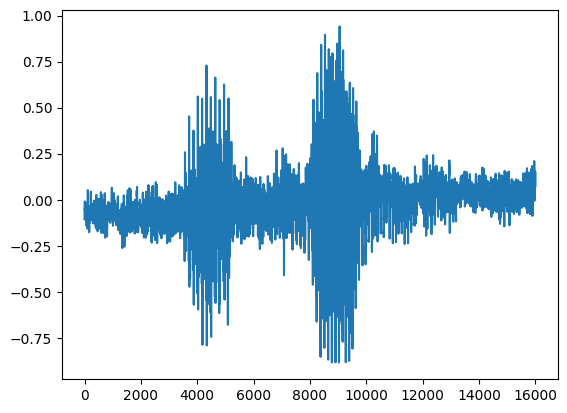

In [4]:
# Ejemplo de carga de un archivo
files = sorted(f for f in os.listdir(DIR_TRAIN) if f.lower().endswith('.wav'))
wave = load_wav_16k_mono(DIR_TRAIN + files[0])
print(files[0], wave.shape)
plt.plot(wave); plt.show()

Celda 4

In [5]:
N_MUESTRAS = 16000

def preprocess(wave):
    wav = wave[:N_MUESTRAS]
    wav = tf.pad(wav, [[0, N_MUESTRAS - tf.shape(wav)[0]]])
    spectrogram = tf.signal.stft(wav, frame_length=255, frame_step=128)
    spectrogram = tf.abs(spectrogram)
    return spectrogram

espectrograma = preprocess(wave)
print('Waveform shape:', wave.shape)
print('Spectrogram shape:', espectrograma.shape)
display.display(display.Audio(wave, rate=16000))

Waveform shape: (16000,)
Spectrogram shape: (124, 129)


Celda 5

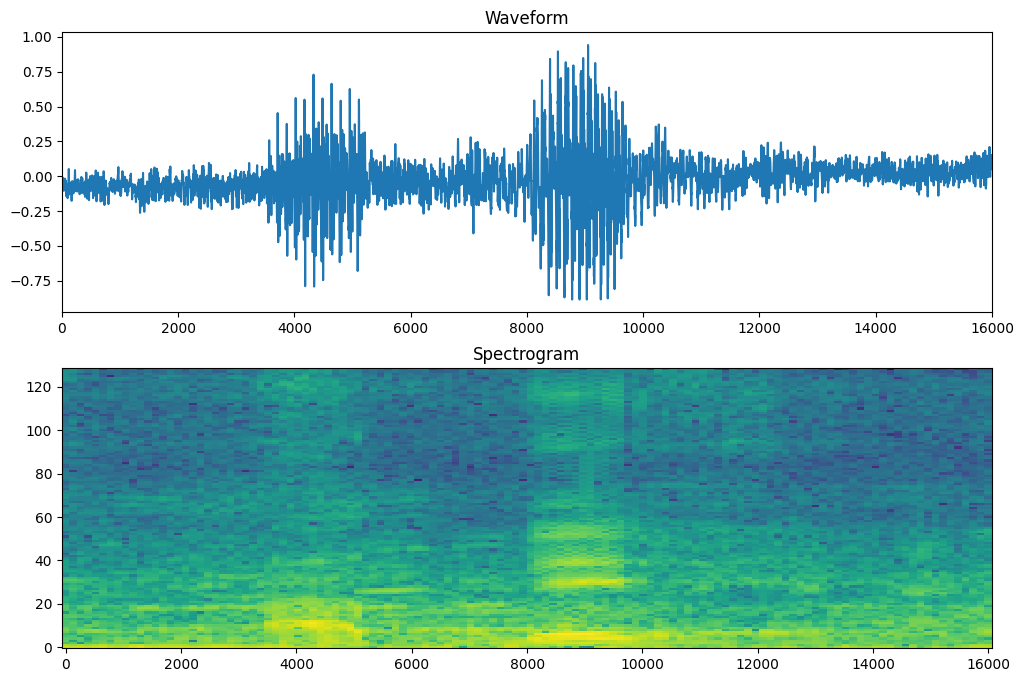

In [6]:
def plot_spectrogram(espectrograma, ax):
    log_spec = np.log(espectrograma.T + 1e-6)
    height, width = log_spec.shape
    X = np.linspace(0, np.size(espectrograma), num=width, dtype=int)
    Y = range(height)
    ax.pcolormesh(X, Y, log_spec)

fig, axes = plt.subplots(2, figsize=(12, 8))
axes[0].plot(np.arange(wave.shape[0]), wave.numpy())
axes[0].set_title('Waveform')
axes[0].set_xlim([0, N_MUESTRAS])
plot_spectrogram(espectrograma.numpy(), axes[1])
axes[1].set_title('Spectrogram')
plt.show()

Celda 6

In [7]:
def cargar_conjunto(directory):
    files = sorted(f for f in os.listdir(directory) if f.lower().endswith('.wav'))
    X = np.stack([preprocess(load_wav_16k_mono(directory + f)).numpy() for f in files])
    y = np.array([CLASES.index(etiqueta(f)) for f in files])
    return X, y, files

Xtrain, ytrain, ftrain = cargar_conjunto(DIR_TRAIN)
Xtest,  ytest,  ftest  = cargar_conjunto(DIR_TEST)


Xtrain = np.log1p(Xtrain)[..., None].astype('float32')
Xtest  = np.log1p(Xtest)[..., None].astype('float32')
mu, sd = Xtrain.mean(), Xtrain.std()
Xtrain = (Xtrain - mu) / sd
Xtest  = (Xtest  - mu) / sd

print('Train:', Xtrain.shape, np.bincount(ytrain))
print('Test :', Xtest.shape,  np.bincount(ytest))

Train: (200, 124, 129, 1) [40 40 40 40 40]
Test : (50, 124, 129, 1) [10 10 10 10 10]


Celda 7 – Las 4 arquitecturas

Todas usan la misma entrada (el espectrograma de la Celda 6), así que el Arduino hace el mismo procesamiento con cualquiera. Todas caben en el Nano en int8.

| Nombre | Idea |
|---|---|
| `original` | La CNN de tu ejercicio: Resizing 48×48 + 3 Conv2D (16, 32, 64). |
| `cnn_bn` | Igual, pero Conv → BatchNorm → ReLU y entrada 64×64 (la BatchNorm se funde con la conv, mejor para int8). |
| `ds_cnn` | Convoluciones *depthwise separable*, como el ejemplo *micro_speech* de TensorFlow para microcontroladores. Menos parámetros. |
| `conv1d` | Convoluciones 1D en el tiempo, con las 129 frecuencias como canales. |

In [8]:
N_CLASES = len(CLASES)

def arq_original():
    return keras.Sequential([
        layers.Input(Xtrain.shape[1:]),
        layers.RandomTranslation(0.1, 0.0, fill_mode='nearest'),   # aumento de datos (solo en entrenamiento)
        layers.Resizing(48, 48),
        layers.Conv2D(16, 3, activation='relu'), layers.BatchNormalization(), layers.MaxPooling2D(),
        layers.Conv2D(32, 3, activation='relu'), layers.BatchNormalization(), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(N_CLASES, activation='softmax'),
    ], name='original')

def arq_cnn_bn():
    capas = [layers.Input(Xtrain.shape[1:]), layers.RandomTranslation(0.1, 0.0, fill_mode='nearest'), layers.Resizing(64, 64)]
    for f in [16, 32, 64]:
        capas += [layers.Conv2D(f, 3, padding='same', use_bias=False), layers.BatchNormalization(), layers.ReLU(), layers.MaxPooling2D()]
    capas += [layers.GlobalAveragePooling2D(), layers.Dropout(0.3), layers.Dense(N_CLASES, activation='softmax')]
    return keras.Sequential(capas, name='cnn_bn')

def arq_ds_cnn():
    capas = [layers.Input(Xtrain.shape[1:]), layers.RandomTranslation(0.1, 0.0, fill_mode='nearest'), layers.Resizing(64, 64),
             layers.Conv2D(32, 3, strides=2, padding='same', use_bias=False), layers.BatchNormalization(), layers.ReLU()]
    for f in [32, 64, 64]:
        capas += [layers.DepthwiseConv2D(3, padding='same', use_bias=False), layers.BatchNormalization(), layers.ReLU(),   # filtro por canal
                  layers.Conv2D(f, 1, use_bias=False), layers.BatchNormalization(), layers.ReLU(),                          # mezcla canales
                  layers.MaxPooling2D()]
    capas += [layers.GlobalAveragePooling2D(), layers.Dropout(0.3), layers.Dense(N_CLASES, activation='softmax')]
    return keras.Sequential(capas, name='ds_cnn')

def arq_conv1d():
    return keras.Sequential([
        layers.Input(Xtrain.shape[1:]), layers.RandomTranslation(0.1, 0.0, fill_mode='nearest'),
        layers.Reshape((Xtrain.shape[1], Xtrain.shape[2])),                 # (tiempo, frecuencias)
        layers.Conv1D(64, 5, padding='same', use_bias=False), layers.BatchNormalization(), layers.ReLU(), layers.MaxPooling1D(2),
        layers.Conv1D(64, 5, padding='same', use_bias=False), layers.BatchNormalization(), layers.ReLU(), layers.MaxPooling1D(2),
        layers.Conv1D(64, 3, padding='same', use_bias=False), layers.BatchNormalization(), layers.ReLU(),
        layers.GlobalAveragePooling1D(), layers.Dropout(0.3), layers.Dense(N_CLASES, activation='softmax'),
    ], name='conv1d')

ARQUITECTURAS = {'original': arq_original, 'cnn_bn': arq_cnn_bn, 'ds_cnn': arq_ds_cnn, 'conv1d': arq_conv1d}
for nombre, f in ARQUITECTURAS.items():
    print(f"{nombre:9s} {f().count_params():7d} parámetros")

original    23813 parámetros
cnn_bn      23957 parámetros
ds_cnn      10213 parámetros
conv1d      75141 parámetros


Celda 8 – Comparar las 4 arquitecturas (tarda unos minutos)

Entrena cada una con 3 semillas distintas y mide el test en Keras y en **int8** (el que va al Nano). Se usan 3 semillas porque con 50 audios de test un solo entrenamiento puede salir mejor o peor por suerte. Si no la quieres correr, sáltala: la Celda 9 entrena directamente la elegida.

In [9]:
def a_int8(m):
    def rep():
        for i in range(len(Xtrain)):
            yield [Xtrain[i:i + 1]]
    c = tf.lite.TFLiteConverter.from_keras_model(m)
    c.optimizations = [tf.lite.Optimize.DEFAULT]
    c.representative_dataset = rep
    c.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    c.inference_input_type = tf.int8
    c.inference_output_type = tf.int8
    return c.convert()

def acc_int8(contenido, X, y):
    inter = tf.lite.Interpreter(model_content=contenido); inter.allocate_tensors()
    ent, sal = inter.get_input_details()[0], inter.get_output_details()[0]
    esc, zp = ent['quantization']
    aciertos = 0
    for i in range(len(X)):
        inter.set_tensor(ent['index'], np.clip(np.round(X[i:i + 1] / esc + zp), -128, 127).astype(np.int8))
        inter.invoke()
        aciertos += int(inter.get_tensor(sal['index'])[0].argmax() == y[i])
    return aciertos / len(X)

def ram_int8_kb(contenido):
    inter = tf.lite.Interpreter(model_content=contenido); inter.allocate_tensors()
    T = {t['index']: t for t in inter.get_tensor_details()}
    tam = lambda i: int(np.prod(T[i]['shape']))
    ops = [o for o in inter._get_ops_details() if o['op_name'] != 'DELEGATE']
    return max(max([tam(i) for i in o['inputs'] if i >= 0 and len(T[i]['shape']) >= 3] + [0]) + sum(tam(i) for i in o['outputs']) for o in ops) / 1024

SEMILLAS = [1, 2, 3]
resultados = {}
for nombre, f in ARQUITECTURAS.items():
    rk, r8 = [], []
    for s_ in SEMILLAS:
        keras.utils.set_random_seed(s_)
        m = f()
        m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        m.fit(Xtrain, ytrain, epochs=80, batch_size=16, verbose=0)
        rk.append((m.predict(Xtest, verbose=0).argmax(1) == ytest).mean())
        q = a_int8(m)
        r8.append(acc_int8(q, Xtest, ytest))
    resultados[nombre] = dict(params=m.count_params(), keras=np.mean(rk), int8=np.mean(r8), int8_min=min(r8), kb=len(q) / 1024, ram=ram_int8_kb(q))
    print(f"{nombre} listo: int8 por semilla {[round(v, 2) for v in r8]}")

print(f"\n{'Arquitectura':12s} {'Parámetros':>10s} {'Keras test':>11s} {'int8 test':>10s} {'int8 peor':>10s} {'Tamaño':>9s} {'RAM int8':>9s}")
for nombre, r in sorted(resultados.items(), key=lambda t: -t[1]['int8']):
    print(f"{nombre:12s} {r['params']:10d} {r['keras']:11.3f} {r['int8']:10.3f} {r['int8_min']:10.3f} {r['kb']:6.1f} KB {r['ram']:6.0f} KB")
mejor = max(resultados, key=lambda k: (resultados[k]['int8'], resultados[k]['int8_min']))
print(f"\nMejor en int8 (promedio de {len(SEMILLAS)} semillas): {mejor}")
keras.utils.set_random_seed(SEED)

Saved artifact at '/tmp/tmprbqdjq5z'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 124, 129, 1), dtype=tf.float32, name='keras_tensor_79')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  133398938578256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398938582096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398938580176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398938580560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398938578064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398938566736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398938575952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398938575760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398938582288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398938580368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13339893858

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Saved artifact at '/tmp/tmp2b_zrh4a'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 124, 129, 1), dtype=tf.float32, name='keras_tensor_93')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  133398972922768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398972920464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398972918160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398972923344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398972919120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398972918928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398972920848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398972923152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398972916240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398972918736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13339897292

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Saved artifact at '/tmp/tmp8v3dkdgn'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 124, 129, 1), dtype=tf.float32, name='keras_tensor_107')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  133398972912016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398972918352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398972910096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398519255440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398972920656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398972921232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398519255056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398519253904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398519254480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398519254672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1333985192

...

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Saved artifact at '/tmp/tmp6cns2gw1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 124, 129, 1), dtype=tf.float32, name='keras_tensor_299')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  133398972923536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398304759760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398304767824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398304759376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398304767056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398304756496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398304767632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398326934992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398304767440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398304766480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1333983269

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


conv1d listo: int8 por semilla [0.88, 1.0, 1.0]

Arquitectura Parámetros  Keras test  int8 test  int8 peor    Tamaño  RAM int8
ds_cnn            10213       1.000      0.993      0.980   26.5 KB     64 KB
cnn_bn            23957       0.973      0.967      0.940   31.2 KB     80 KB
conv1d            75141       0.960      0.960      0.880   87.8 KB     48 KB
original          23813       0.967      0.953      0.940   32.6 KB     66 KB

Mejor en int8 (promedio de 3 semillas): ds_cnn


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Celda 9 – Entrenar la arquitectura elegida

Model: "ds_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_translation_16           │ (None, 124, 129, 1)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing_12 (Resizing)          │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_40 (Conv2D)              │ (None, 32, 32, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_60          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_52 (ReLU)                 │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_12             │ (None, 32, 32, 32)     │           288 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_61          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_53 (ReLU)                 │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_41 (Conv2D)              │ (None, 32, 32, 32)     │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_62          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_54 (ReLU)                 │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_36 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_13             │ (None, 16, 16, 32)     │           288 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_63          │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_55 (ReLU)                 │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_42 (Conv2D)              │ (None, 16, 16, 64)     │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_64          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_56 (ReLU)                 │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_37 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_14             │ (None, 8, 8, 64)       │           576 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 10,213 (39.89 KB)

 Trainable params: 9,573 (37.39 KB)

 Non-trainable params: 640 (2.50 KB)

Arquitectura: ds_cnn | accuracy final (train): 1.0


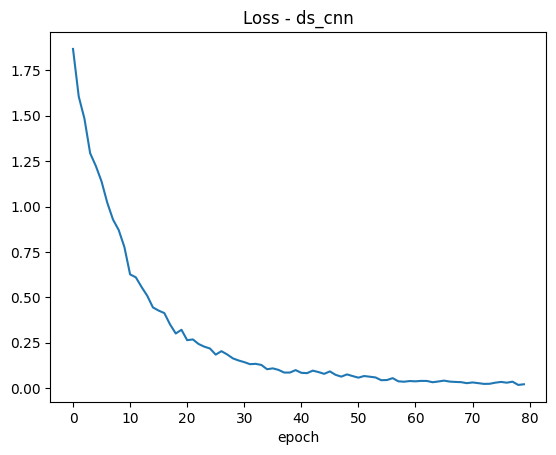

In [10]:
ARQUITECTURA = 'ds_cnn'      # 'original' | 'cnn_bn' | 'ds_cnn' | 'conv1d'

keras.utils.set_random_seed(SEED)
model = ARQUITECTURAS[ARQUITECTURA]()
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

history = model.fit(Xtrain, ytrain, epochs=80, batch_size=16, verbose=0)
print('Arquitectura:', ARQUITECTURA, '| accuracy final (train):', history.history['accuracy'][-1])
plt.plot(history.history['loss']); plt.title(f'Loss - {ARQUITECTURA}'); plt.xlabel('epoch'); plt.show()

Celda 10: matrices de confusión

== Entrenamiento: accuracy = 1.0000
              precision    recall  f1-score   support

       dolex      1.000     1.000     1.000        40
       advil      1.000     1.000     1.000        40
    aspirina      1.000     1.000     1.000        40
   omeprazol      1.000     1.000     1.000        40
    losartan      1.000     1.000     1.000        40

    accuracy                          1.000       200
   macro avg      1.000     1.000     1.000       200
weighted avg      1.000     1.000     1.000       200



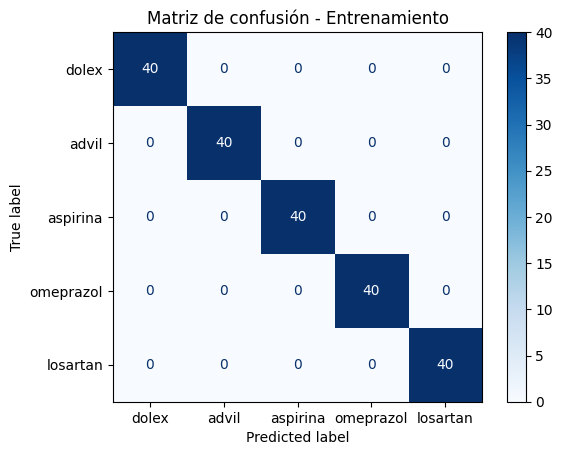

== Prueba (test): accuracy = 1.0000
              precision    recall  f1-score   support

       dolex      1.000     1.000     1.000        10
       advil      1.000     1.000     1.000        10
    aspirina      1.000     1.000     1.000        10
   omeprazol      1.000     1.000     1.000        10
    losartan      1.000     1.000     1.000        10

    accuracy                          1.000        50
   macro avg      1.000     1.000     1.000        50
weighted avg      1.000     1.000     1.000        50



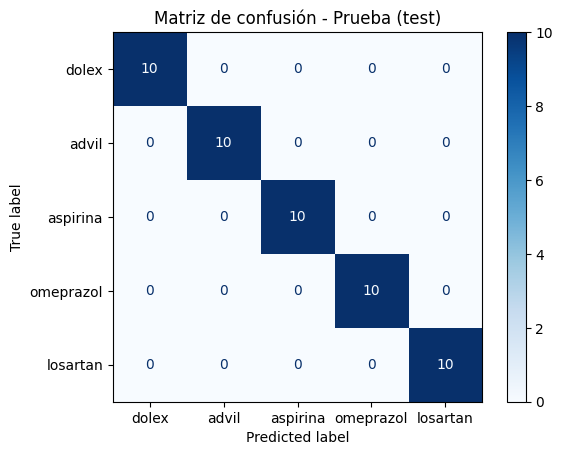

In [11]:
for nombre, X, y in [('Entrenamiento', Xtrain, ytrain), ('Prueba (test)', Xtest, ytest)]:
    pred = model.predict(X, verbose=0).argmax(axis=1)
    print(f'== {nombre}: accuracy = {(pred == y).mean():.4f}')
    print(classification_report(y, pred, labels=range(len(CLASES)), target_names=CLASES, digits=3, zero_division=0))
    ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=range(len(CLASES))), display_labels=CLASES).plot(cmap='Blues')
    plt.title(f'Matriz de confusión - {nombre}'); plt.show()

celda 11

In [12]:
# Se guarda el modelo en formato Keras
model.save('KWS_model.h5')
model.save('KWS_model.keras')

celda 12

In [13]:
# Se convierte el modelo a TensorFlow Lite (sin cuantizar)
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_f32 = converter.convert()
open("/content/KWS_f32.tflite", "wb").write(tflite_f32)
print("TFLite sin cuantizar:", round(len(tflite_f32) / 1024, 1), "KB")

Saved artifact at '/tmp/tmp6ou2w_tf'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 124, 129, 1), dtype=tf.float32, name='keras_tensor_316')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  133398318898960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398474534608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398474537872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398474538832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398474523280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398319085328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398319076688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398319074768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398319080720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398319075728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1333983190

celda 13

In [14]:
conv16 = tf.lite.TFLiteConverter.from_keras_model(model)
conv16.optimizations = [tf.lite.Optimize.DEFAULT]
conv16.target_spec.supported_types = [tf.float16]
tflite_f16 = conv16.convert()
open("/content/KWS_f16.tflite", "wb").write(tflite_f16)
print("TFLite float16:", round(len(tflite_f16) / 1024, 1), "KB")

Saved artifact at '/tmp/tmpwb20rbk6'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 124, 129, 1), dtype=tf.float32, name='keras_tensor_316')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  133398318898960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398474534608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398474537872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398474538832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398474523280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398319085328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398319076688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398319074768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398319080720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398319075728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1333983190

celda 14

In [15]:
def dataset_representativo():
    for i in range(len(Xtrain)):
        yield [Xtrain[i:i + 1]]

conv8 = tf.lite.TFLiteConverter.from_keras_model(model)
conv8.optimizations = [tf.lite.Optimize.DEFAULT]
conv8.representative_dataset = dataset_representativo
conv8.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv8.inference_input_type = tf.int8
conv8.inference_output_type = tf.int8
tflite_int8 = conv8.convert()
open("/content/KWS_int8.tflite", "wb").write(tflite_int8)
print("TFLite int8:", round(len(tflite_int8) / 1024, 1), "KB")

Saved artifact at '/tmp/tmp9b2dkfjw'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 124, 129, 1), dtype=tf.float32, name='keras_tensor_316')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  133398318898960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398474534608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398474537872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398474538832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398474523280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398319085328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398319076688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398319074768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398319080720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133398319075728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1333983190

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


TFLite int8: 26.5 KB


celda 15

In [16]:
def predecir_tflite(contenido, X):
    inter = tf.lite.Interpreter(model_content=contenido)
    inter.allocate_tensors()
    ent, sal = inter.get_input_details()[0], inter.get_output_details()[0]
    probs = []
    for i in range(len(X)):
        x = X[i:i + 1]
        if ent['dtype'] == np.int8:                      # entrada: float -> int8
            esc, zp = ent['quantization']
            x = np.clip(np.round(x / esc + zp), -128, 127).astype(np.int8)
        inter.set_tensor(ent['index'], x)
        inter.invoke()
        s = inter.get_tensor(sal['index'])
        if sal['dtype'] == np.int8:                      # salida: int8 -> float
            esc, zp = sal['quantization']
            s = (s.astype(np.float32) - zp) * esc
        probs.append(s[0])
    return np.array(probs)

celda 16

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


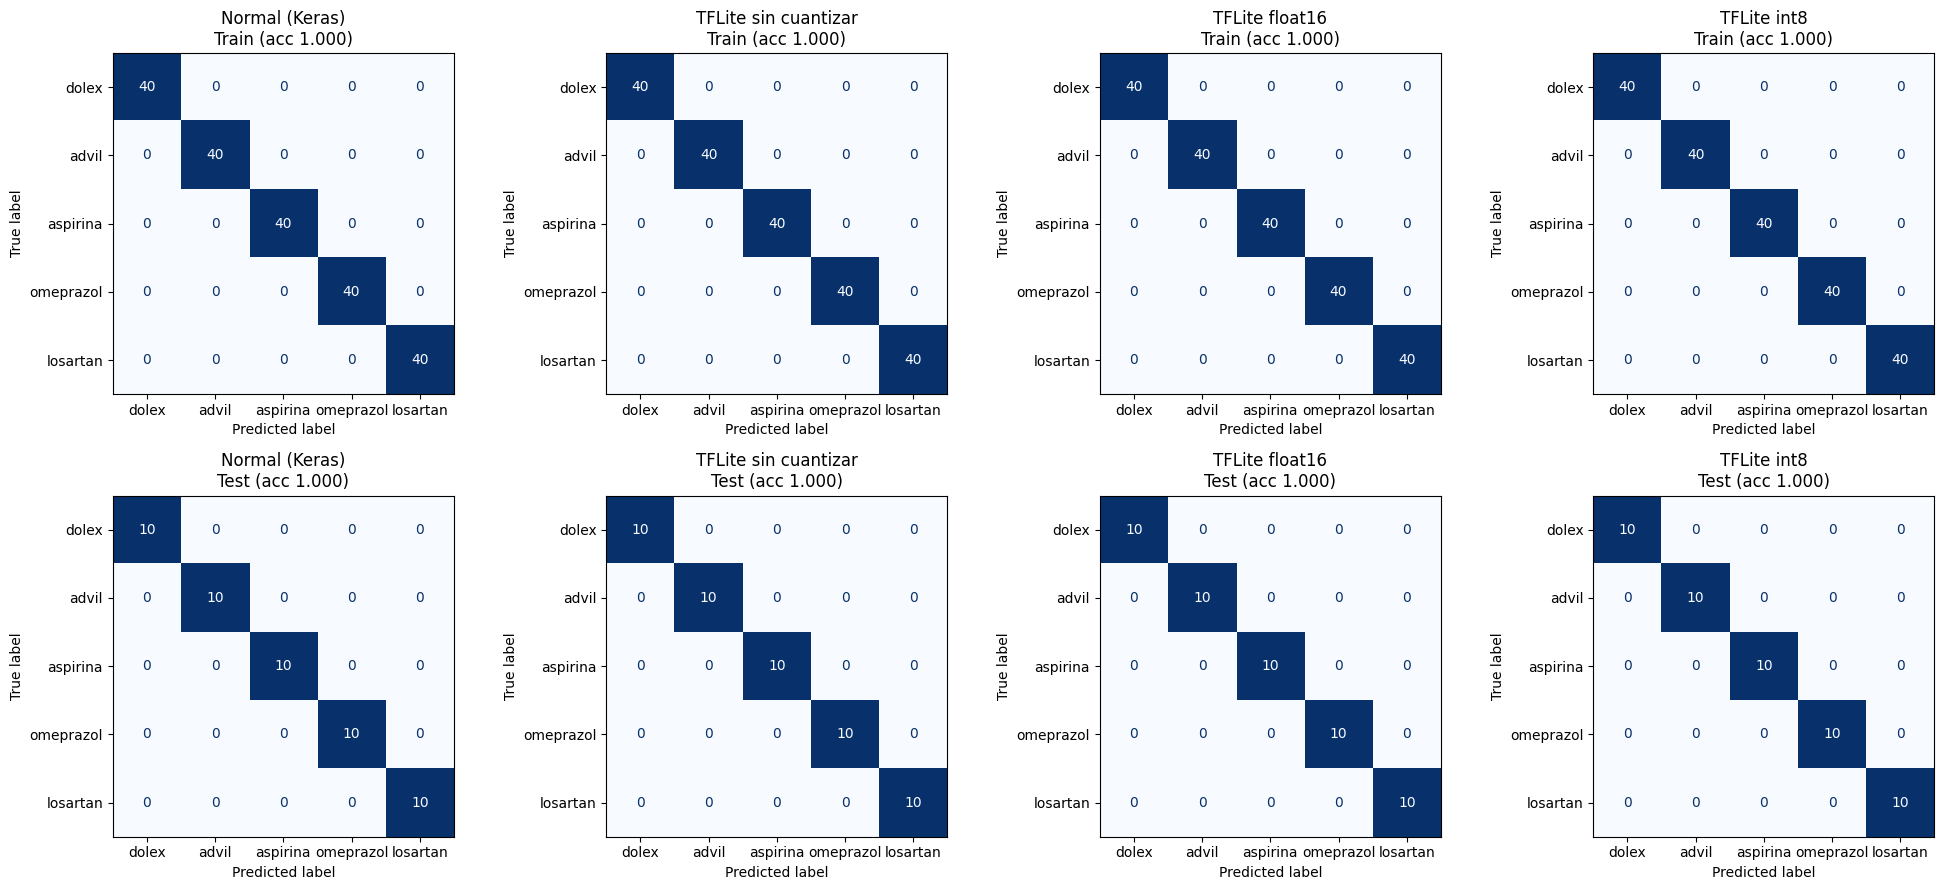

Modelo                     Tamaño  Acc train   Acc test  Dif. prob. vs normal (test)
Normal (Keras)             39.9 KB      1.000      1.000                      0.00000
TFLite sin cuantizar       44.1 KB      1.000      1.000                      0.00000
TFLite float16             29.6 KB      1.000      1.000                      0.00004
TFLite int8                26.5 KB      1.000      1.000                      0.00164


In [17]:
modelos = {
    'Normal (Keras)':          lambda X: model.predict(X, verbose=0),
    'TFLite sin cuantizar':    lambda X: predecir_tflite(tflite_f32, X),
    'TFLite float16':          lambda X: predecir_tflite(tflite_f16, X),
    'TFLite int8':             lambda X: predecir_tflite(tflite_int8, X),
}
tam = {'Normal (Keras)': model.count_params() * 4, 'TFLite sin cuantizar': len(tflite_f32),
       'TFLite float16': len(tflite_f16), 'TFLite int8': len(tflite_int8)}
conjuntos = [('Train', Xtrain, ytrain), ('Test', Xtest, ytest)]

probs = {(m, c): f(X) for m, f in modelos.items() for c, X, y in conjuntos}

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for r, (cnom, X, y) in enumerate(conjuntos):
    for c, mnom in enumerate(modelos):
        pred = probs[(mnom, cnom)].argmax(axis=1)
        ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=range(len(CLASES))), display_labels=CLASES).plot(ax=axes[r, c], cmap='Blues', colorbar=False)
        axes[r, c].set_title(f'{mnom}\n{cnom} (acc {(pred == y).mean():.3f})')
plt.tight_layout(); plt.show()

print(f"{'Modelo':22s} {'Tamaño':>10s} {'Acc train':>10s} {'Acc test':>10s} {'Dif. prob. vs normal (test)':>28s}")
base = probs[('Normal (Keras)', 'Test')]
for m in modelos:
    a_tr = (probs[(m, 'Train')].argmax(1) == ytrain).mean()
    a_te = (probs[(m, 'Test')].argmax(1) == ytest).mean()
    dif = np.abs(probs[(m, 'Test')] - base).mean()
    print(f"{m:22s} {tam[m]/1024:8.1f} KB {a_tr:10.3f} {a_te:10.3f} {dif:28.5f}")

Celda 17 – ¿Cuál cabe en el Arduino Nano 33 BLE Sense?

El Nano tiene **1 MB de flash** (donde se guarda el modelo) y **256 KB de RAM** (donde van los cálculos intermedios, el audio y el programa). Las tres versiones caben en flash; lo que decide es la RAM. En el Arduino (TensorFlow Lite Micro) el float16 se ejecuta como float32, así que gasta la misma RAM que el sin cuantizar.

In [18]:
NANO_FLASH_KB, NANO_RAM_KB = 1024, 256
OTROS_KB = 16000 * 2 * 2 / 1024 + 50      # audio de 1 s en doble buffer (int16) + programa / Mbed OS (aprox.)

def ram_calculos_kb(contenido, bytes_por_valor):
    """Pico de memoria de los cálculos: la capa que más ocupa (entrada + salida)."""
    inter = tf.lite.Interpreter(model_content=contenido)
    inter.allocate_tensors()
    T = {t['index']: t for t in inter.get_tensor_details()}
    tam = lambda i: int(np.prod(T[i]['shape'])) * bytes_por_valor
    ops = [o for o in inter._get_ops_details() if o['op_name'] != 'DELEGATE']
    return max(max([tam(i) for i in o['inputs'] if i >= 0 and len(T[i]['shape']) == 4] + [0]) + sum(tam(i) for i in o['outputs']) for o in ops) / 1024

print(f"{'Modelo':22s} {'Flash':>10s} {'RAM cálculos':>13s} {'RAM total aprox.':>17s}   ¿Cabe en el Nano?")
for nombre, cont, bpv in [('TFLite sin cuantizar', tflite_f32, 4), ('TFLite float16', tflite_f16, 4), ('TFLite int8', tflite_int8, 1)]:
    ram = ram_calculos_kb(cont, bpv)
    total = ram + OTROS_KB
    cabe = '✅ sí' if total < 0.8 * NANO_RAM_KB else '❌ no'
    print(f"{nombre:22s} {len(cont)/1024:7.1f} KB {ram:10.1f} KB {total:14.1f} KB   {cabe}")
print(f"\nEl Nano tiene {NANO_FLASH_KB} KB de flash y {NANO_RAM_KB} KB de RAM (se deja ~20 % libre para el resto del programa).")

Modelo                      Flash  RAM cálculos  RAM total aprox.   ¿Cabe en el Nano?
TFLite sin cuantizar      44.1 KB      256.0 KB          368.5 KB   ❌ no
TFLite float16            29.6 KB      256.0 KB          368.5 KB   ❌ no
TFLite int8               26.5 KB       64.0 KB          176.5 KB   ✅ sí

El Nano tiene 1024 KB de flash y 256 KB de RAM (se deja ~20 % libre para el resto del programa).


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Celda 18 – Lógica del dispensador

In [19]:
def preparar(waves):
    """Audios (N, 16000) -> entrada del modelo, con el MISMO procesamiento de la celda 6."""
    X = np.stack([preprocess(tf.constant(w, dtype=tf.float32)).numpy() for w in np.atleast_2d(waves)])
    return ((np.log1p(X)[..., None] - mu) / sd).astype('float32')

def ajustar(w, n=N_MUESTRAS):
    w = np.asarray(w, dtype='float32')[:n]
    return np.pad(w, (0, n - len(w)))

def rms(w):
    return float(np.sqrt(np.mean(np.square(w))))

# Detector de voz: si la ventana tiene menos volumen que esto, es silencio y NO se clasifica.
# Se calcula con tus audios de train (el 5 % más bajo de las palabras, con margen).
_rms_train = [rms(load_wav_16k_mono(DIR_TRAIN + f).numpy()) for f in ftrain if etiqueta(f) != DESCONOCIDO]
RMS_MIN = 0.3 * float(np.percentile(_rms_train, 5))
print(f"RMS mínimo para considerar que hay voz: {RMS_MIN:.4f}")

def decidir(prob):
    """Devuelve la pastilla a dispensar o None (confianza baja o 'desconocido')."""
    k = int(np.argmax(prob))
    if CLASES[k] == DESCONOCIDO or prob[k] < UMBRAL:
        return None
    return CLASES[k]

def accion(pastilla):
    c = COMPARTIMENTO[pastilla]
    return f"✅ DISPENSAR {pastilla} -> compartimento {c}, servo {ANGULO_SERVO[c]}° y vuelve a {ANGULO_REPOSO}°"

class Dispensador:
    """Escucha continua: dispensa solo si la misma pastilla aparece en CONFIRMACIONES ventanas seguidas."""
    def __init__(self):
        self.ultima, self.cuenta, self.bloqueo_hasta = None, 0, -1.0

    def actualizar(self, prob, t):
        if t < self.bloqueo_hasta:                 # enfriamiento después de dispensar
            return None
        cand = decidir(prob)
        if cand is None:
            self.ultima, self.cuenta = None, 0
            return None
        self.cuenta = self.cuenta + 1 if cand == self.ultima else 1
        self.ultima = cand
        if self.cuenta >= CONFIRMACIONES:
            self.ultima, self.cuenta = None, 0
            self.bloqueo_hasta = t + ENFRIAMIENTO_S
            return cand
        return None

def seleccionar_palabra(wave, nombre=''):
    """Un audio de ~1 s: qué entendió y qué haría el dispensador (con el modelo int8)."""
    wave = ajustar(wave)
    if rms(wave) < RMS_MIN:
        print(f"{nombre:40s} silencio (no hay voz)  ->  ⛔ no dispensa")
        return None
    p = predecir_tflite(tflite_int8, preparar(wave))[0]
    k = int(p.argmax())
    cand = decidir(p)
    print(f"{nombre:40s} entendí: {CLASES[k]:13s} ({p[k]*100:5.1f}%)  ->  {accion(cand) if cand else '⛔ no dispensa'}")
    return cand
print("Dispensador listo | umbral", UMBRAL)

RMS mínimo para considerar que hay voz: 0.0258
Dispensador listo | umbral 0.8


Celda 19 – El dispensador sobre todos los audios de test

In [20]:
correctas = 0
for f, y in zip(ftest, ytest):
    cand = seleccionar_palabra(load_wav_16k_mono(DIR_TEST + f).numpy(), f[:40])
    esperado = None if CLASES[y] == DESCONOCIDO else CLASES[y]
    correctas += (cand == esperado)
print(f"\nDecisiones correctas del dispensador en test: {correctas}/{len(ytest)} ({correctas/len(ytest):.1%})")
print("(una decisión 'no dispensa' por confianza baja cuenta como error, pero es un error seguro)")

advil.75ru2r3r.ingestion-695fc665dd-7nlh entendí: advil         ( 99.2%)  ->  ✅ DISPENSAR advil -> compartimento 2, servo 72° y vuelve a 0°
advil.75ru2r3r.ingestion-695fc665dd-7nlh entendí: advil         ( 99.6%)  ->  ✅ DISPENSAR advil -> compartimento 2, servo 72° y vuelve a 0°
advil.75ru2r3r.ingestion-695fc665dd-7nlh entendí: advil         ( 99.6%)  ->  ✅ DISPENSAR advil -> compartimento 2, servo 72° y vuelve a 0°
advil.75ruan5e.ingestion-695fc665dd-vkcz entendí: advil         ( 93.8%)  ->  ✅ DISPENSAR advil -> compartimento 2, servo 72° y vuelve a 0°
advil.75rugii1.ingestion-695fc665dd-624s entendí: advil         ( 86.7%)  ->  ✅ DISPENSAR advil -> compartimento 2, servo 72° y vuelve a 0°
advil.75rugii1.ingestion-695fc665dd-624s entendí: advil         ( 99.6%)  ->  ✅ DISPENSAR advil -> compartimento 2, servo 72° y vuelve a 0°
advil.75rugii1.ingestion-695fc665dd-624s entendí: advil         ( 99.2%)  ->  ✅ DISPENSAR advil -> compartimento 2, servo 72° y vuelve a 0°
advil.75ruok2q.inges

Celda 20 – Escucha continua (demostración)

Orden en el audio: ['dolex', 'advil', 'aspirina', 'omeprazol', 'losartan']
t= 2.00s  ✅ DISPENSAR dolex -> compartimento 1, servo 36° y vuelve a 0°
t= 4.00s  ✅ DISPENSAR advil -> compartimento 2, servo 72° y vuelve a 0°
t= 6.00s  ✅ DISPENSAR aspirina -> compartimento 3, servo 108° y vuelve a 0°
t= 7.75s  ✅ DISPENSAR omeprazol -> compartimento 4, servo 144° y vuelve a 0°
t=10.00s  ✅ DISPENSAR losartan -> compartimento 5, servo 180° y vuelve a 0°


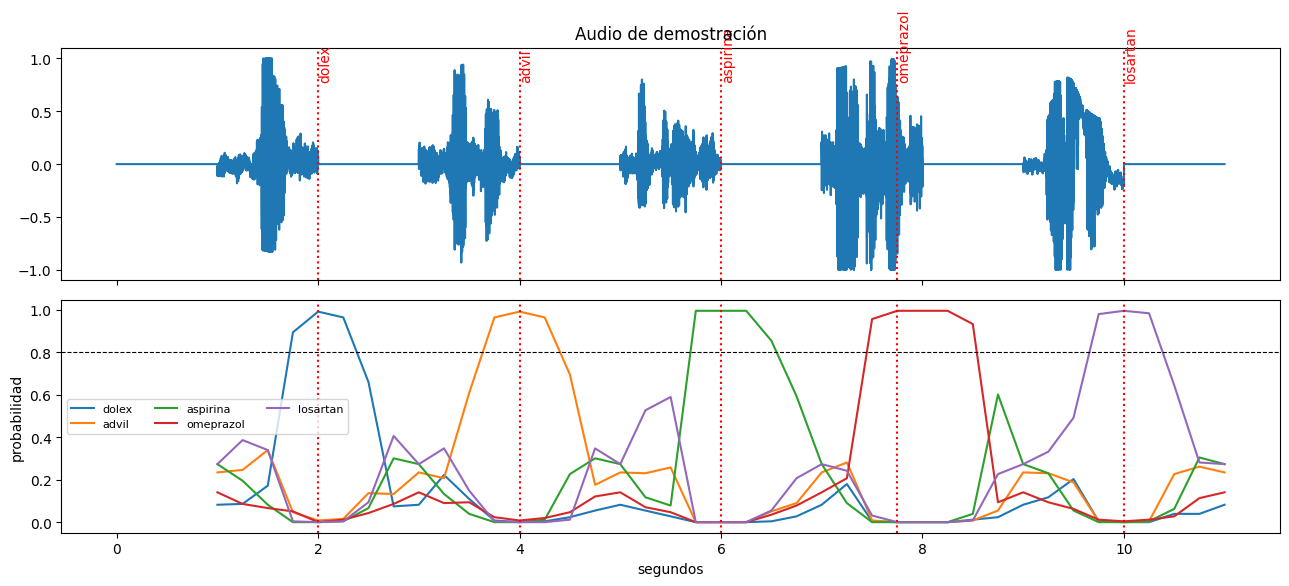


Pastillas dispensadas: ['dolex', 'advil', 'aspirina', 'omeprazol', 'losartan']


In [21]:
def escuchar_continuo(wave, titulo=''):
    paso = int(PASO_S * 16000)
    wave = ajustar(wave, max(len(wave), N_MUESTRAS))
    inicios = np.arange(0, len(wave) - N_MUESTRAS + 1, paso)
    P = predecir_tflite(tflite_int8, preparar(np.stack([wave[i:i + N_MUESTRAS] for i in inicios])))
    disp, eventos = Dispensador(), []
    for i, p in zip(inicios, P):
        t = i / 16000 + 1.0
        if rms(wave[i:i + N_MUESTRAS]) < RMS_MIN:      # silencio: no se clasifica
            p = np.zeros(len(CLASES))
        cand = disp.actualizar(p, t)
        if cand:
            print(f"t={t:5.2f}s  {accion(cand)}")
            eventos.append((t, cand))
    t = inicios / 16000 + 1.0
    fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
    ax[0].plot(np.arange(len(wave)) / 16000, wave); ax[0].set_title(f'Audio {titulo}')
    for col, c_ in enumerate(CLASES):
        ax[1].plot(t, P[:, col], label=c_)
    ax[1].axhline(UMBRAL, color='k', ls='--', lw=0.8); ax[1].set_ylabel('probabilidad'); ax[1].legend(ncol=3, fontsize=8)
    for te, nombre in eventos:
        for a in ax: a.axvline(te, color='r', ls=':')
        ax[0].text(te, 0.8 * (np.abs(wave).max() + 1e-6), nombre, color='r', rotation=90)
    ax[1].set_xlabel('segundos'); plt.tight_layout(); plt.show()
    return eventos

def armar_demo():
    """Un audio de test de cada clase, separados por 1 s de silencio."""
    partes, silencio = [], np.zeros(16000, dtype='float32')
    for c in CLASES:
        f = next(f for f in ftest if etiqueta(f) == c)
        partes += [silencio, ajustar(load_wav_16k_mono(DIR_TEST + f).numpy())]
    print("Orden en el audio:", CLASES)
    return np.concatenate(partes + [silencio])

RUTA_LARGA = None          # ruta de un audio largo tuyo; None = demostración con test
wave_largo = armar_demo() if RUTA_LARGA is None else load_wav_16k_mono(RUTA_LARGA).numpy()
eventos = escuchar_continuo(wave_largo, 'de demostración' if RUTA_LARGA is None else RUTA_LARGA)
print("\nPastillas dispensadas:", [n for _, n in eventos])

Celda 21 – Exportar el paquete (para el Arduino, más adelante)

In [22]:
inter = tf.lite.Interpreter(model_content=tflite_int8)
ent, sal = inter.get_input_details()[0], inter.get_output_details()[0]
config = {
    'arquitectura': ARQUITECTURA, 'clases': CLASES, 'fs': 16000, 'n_muestras': N_MUESTRAS,
    'espectrograma': {'frame_length': 255, 'frame_step': 128, 'fft_length': 256, 'ventana': 'hann periódica',
                      'forma': list(Xtrain.shape[1:3])},
    'normalizacion': {'paso_1': 'log1p(magnitud)', 'paso_2': '(x - mu) / sd', 'mu': float(mu), 'sd': float(sd)},
    'int8_entrada': {'escala': float(ent['quantization'][0]), 'zero_point': int(ent['quantization'][1])},
    'int8_salida':  {'escala': float(sal['quantization'][0]), 'zero_point': int(sal['quantization'][1])},
    'dispensador': {'umbral': UMBRAL, 'confirmaciones': CONFIRMACIONES, 'paso_s': PASO_S, 'enfriamiento_s': ENFRIAMIENTO_S,
                    'compartimento': COMPARTIMENTO, 'angulo_servo': {str(k): v for k, v in ANGULO_SERVO.items()},
                    'angulo_reposo': ANGULO_REPOSO, 'rms_min_voz': RMS_MIN},
}
with open('/content/config_dispensador.json', 'w') as f:
    json.dump(config, f, indent=2, ensure_ascii=False)

def a_c_array(datos, nombre):
    filas = ['  ' + ', '.join(f'0x{b:02x}' for b in datos[i:i + 12]) + ',' for i in range(0, len(datos), 12)]
    return f"alignas(16) const unsigned char {nombre}[] = {{\n" + "\n".join(filas) + f"\n}};\nconst unsigned int {nombre}_len = {len(datos)};\n"
open('/content/KWS_int8.h', 'w').write(a_c_array(tflite_int8, 'kws_int8_tflite'))

DIR_EXPORT = BASE + 'export/'
os.makedirs(DIR_EXPORT, exist_ok=True)
for a in ['KWS_model.h5', 'KWS_model.keras', '/content/KWS_f32.tflite', '/content/KWS_f16.tflite',
          '/content/KWS_int8.tflite', '/content/KWS_int8.h', '/content/config_dispensador.json']:
    shutil.copy(a, DIR_EXPORT + os.path.basename(a))
print("Paquete guardado en", DIR_EXPORT)
for a in sorted(os.listdir(DIR_EXPORT)):
    print(f"   {a:26s} {os.path.getsize(DIR_EXPORT + a)/1024:8.1f} KB")

Paquete guardado en /content/gdrive/MyDrive/IA/audio_micro/export/
   KWS_f16.tflite                 29.6 KB
   KWS_f32.tflite                 44.1 KB
   KWS_int8.h                    163.6 KB
   KWS_int8.tflite                26.5 KB
   KWS_model.h5                  246.2 KB
   KWS_model.keras               229.2 KB
   config_dispensador.json         1.0 KB


Celda 22 – Probar con audios subidos

In [23]:
from google.colab import files
subido = files.upload()                    # uno o varios .wav de 16 kHz mono
for nombre in subido:
    seleccionar_palabra(load_wav_16k_mono(nombre).numpy(), nombre)

Celda 23 – Probar con el micrófono del computador

⚠️ El modelo se entrenó solo con el micrófono del Nano. El del computador suena distinto (volumen, filtros), así que aquí puede confundirse aunque en el Nano funcione bien. La prueba que cuenta es en el Nano.

1. Ejecuta la celda y presiona el botón azul **🎤 Presiona para grabar**.
2. Espera la cuenta regresiva **3… 2… 1…**
3. Cuando el cuadro se ponga **rojo y diga ¡HABLA AHORA!**, di la palabra. La barra roja muestra cuánto tiempo queda y la verde, si el micrófono te está escuchando.
4. Para otra prueba, vuelve a ejecutar la celda.

In [34]:
from google.colab.output import eval_js

SEGUNDOS_GRABACION = 2.5      # tiempo que dura el cuadro rojo "¡HABLA AHORA!"

JS_GRABAR = """
new Promise(async (resolve, reject) => {
  const MS = __MS__;
  const css = (el, s) => { el.style.cssText = s; return el; };
  const caja = css(document.createElement('div'), 'font-family:sans-serif;padding:18px;border-radius:14px;background:#f1f3f4;width:380px;text-align:center;transition:background .2s');
  const titulo = css(document.createElement('div'), 'font-size:26px;font-weight:bold;margin-bottom:12px;color:#202124');
  const sub = css(document.createElement('div'), 'font-size:14px;color:#5f6368;margin-bottom:12px');
  const boton = css(document.createElement('button'), 'font-size:18px;padding:10px 20px;border-radius:10px;border:none;background:#1a73e8;color:white;cursor:pointer');
  const barra = (color) => {
    const fondo = css(document.createElement('div'), 'height:12px;background:#dadce0;border-radius:6px;margin-top:10px;overflow:hidden');
    const relleno = css(document.createElement('div'), 'height:100%;width:0;background:' + color);
    fondo.appendChild(relleno); return [fondo, relleno];
  };
  const [tiempoFondo, tiempoBarra] = barra('#d93025');
  const [nivelFondo, nivelBarra] = barra('#34a853');
  titulo.textContent = 'Di el nombre de la pastilla';
  sub.textContent = 'Cuando estés listo, presiona el botón';
  boton.textContent = '🎤 Presiona para grabar';
  caja.append(titulo, sub, boton, tiempoFondo, nivelFondo);
  document.body.appendChild(caja);

  await new Promise(r => boton.onclick = r);
  boton.remove();
  titulo.textContent = 'Preparando micrófono...';
  sub.textContent = 'Si el navegador pregunta, dale permiso';

  let stream;
  try {
    stream = await navigator.mediaDevices.getUserMedia({audio: {autoGainControl: true, noiseSuppression: false, echoCancellation: false}});
  } catch (e) {
    titulo.textContent = '❌ Sin permiso para el micrófono';
    sub.textContent = 'Permite el micrófono en el navegador y vuelve a ejecutar la celda';
    reject(e); return;
  }

  // medidor de volumen (barra verde)
  const ctx = new AudioContext();
  const analizador = ctx.createAnalyser(); analizador.fftSize = 1024;
  ctx.createMediaStreamSource(stream).connect(analizador);
  const datos = new Float32Array(analizador.fftSize);
  let midiendo = true;
  (function medir() {
    if (!midiendo) return;
    analizador.getFloatTimeDomainData(datos);
    let suma = 0; for (const v of datos) suma += v * v;
    const db = 20 * Math.log10(Math.sqrt(suma / datos.length) + 1e-9);      // -60 dB (silencio) ... 0 dB (máximo)
    nivelBarra.style.width = Math.max(0, Math.min(100, (db + 60) / 50 * 100)) + '%';
    requestAnimationFrame(medir);
  })();

  // cuenta regresiva
  sub.textContent = 'Prepárate...';
  for (const n of [3, 2, 1]) { titulo.textContent = n + '...'; await new Promise(r => setTimeout(r, 700)); }

  // grabación
  const rec = new MediaRecorder(stream);
  const trozos = [];
  rec.ondataavailable = e => trozos.push(e.data);
  rec.onstop = () => {
    midiendo = false;
    stream.getTracks().forEach(t => t.stop()); ctx.close();
    caja.style.background = '#e6f4ea'; titulo.style.color = '#188038';
    titulo.textContent = '✅ Grabación lista'; sub.textContent = 'Procesando...';
    tiempoBarra.style.width = '0'; nivelBarra.style.width = '0';
    const lector = new FileReader();
    lector.onloadend = () => resolve(lector.result);
    lector.readAsDataURL(new Blob(trozos));
  };
  await new Promise(r => { rec.onstart = r; rec.start(); });
  caja.style.background = '#fce8e6'; titulo.style.color = '#d93025';
  titulo.textContent = '🔴 ¡HABLA AHORA!'; sub.textContent = 'Di la palabra una vez, claro';
  const t0 = performance.now();
  (function reloj() {
    const f = Math.min(1, (performance.now() - t0) / MS);
    tiempoBarra.style.width = (100 * (1 - f)) + '%';
    if (f < 1) requestAnimationFrame(reloj);
  })();
  setTimeout(() => rec.stop(), MS);
});
"""

def grabar_microfono(segundos=SEGUNDOS_GRABACION, archivo='mic.wav'):
    data = eval_js(JS_GRABAR.replace('__MS__', str(int(segundos * 1000))))
    with open('mic_original', 'wb') as f:
        f.write(b64decode(data.split(',')[1]))
    subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', 'mic_original', '-ar', '16000', '-ac', '1', '-sample_fmt', 's16', archivo], check=True)
    return archivo

def palabra_en_grabacion(wave):
    """Revisa toda la grabación en ventanas de 1 s (cada 0.1 s) y se queda con la más segura que tenga voz."""
    wave = ajustar(wave, max(len(wave), N_MUESTRAS))
    inicios = [i for i in range(0, len(wave) - N_MUESTRAS + 1, 1600) if rms(wave[i:i + N_MUESTRAS]) >= RMS_MIN]
    if not inicios:
        return None
    P = predecir_tflite(tflite_int8, preparar(np.stack([wave[i:i + N_MUESTRAS] for i in inicios])))
    P_pal = P.copy()
    if DESCONOCIDO in CLASES:
        P_pal[:, CLASES.index(DESCONOCIDO)] = 0
    return P[int(P_pal.max(1).argmax())]

ruta_mic = grabar_microfono()
wave_mic = load_wav_16k_mono(ruta_mic).numpy()
pico_mic = float(np.abs(wave_mic).max())
print(f"Nivel máximo de la grabación: {pico_mic:.2f}  (tus audios del Nano llegan casi a 1.0)")
if 0 < pico_mic < 0.1:
    print("⚠️ Se grabó muy bajo: habla más fuerte o más cerca del micrófono, o sube el volumen de entrada en tu computador.")
if pico_mic > 0:
    display.display(display.Audio(wave_mic, rate=16000))     # para escuchar lo que se grabó
p = palabra_en_grabacion(wave_mic)
if p is None:
    print("🤫 No se escuchó voz (o el volumen está muy bajo). Acércate al micrófono y vuelve a ejecutar la celda.")
else:
    k = int(p.argmax())
    cand = decidir(p)
    print(f"Entendí: {CLASES[k]} ({p[k]*100:.1f}%)")
    print(accion(cand) if cand else f"⛔ No dispensa (confianza menor a {UMBRAL:.0%} o palabra desconocida): repite más claro")
    for c_, v in sorted(zip(CLASES, p), key=lambda t: -t[1]):
        print(f"   {c_:14s} {'█' * int(v * 30):30s} {v*100:5.1f}%")

Nivel máximo de la grabación: 1.00  (tus audios del Nano llegan casi a 1.0)


Entendí: losartan (96.9%)
✅ DISPENSAR losartan -> compartimento 5, servo 180° y vuelve a 0°
   losartan       █████████████████████████████   96.9%
   omeprazol                                       2.7%
   advil                                           0.4%
   dolex                                           0.0%
   aspirina                                        0.0%


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
